[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_tails/BA_L3_tails.ipynb)

# BA_L3_tails: Heavy tails of Bitcoin standardised residuals

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Standardised residuals of a GARCH(1,1)-t model for Bitcoin, 2018 to 18 September 2026: histogram on a log scale against the Normal and the fitted Student-t, and the number of days with |z| above a threshold, observed against expected under each distribution.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Model.** $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$, with the GARCH(1,1) recursion of Bollerslev (1986)
$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 , $$
and $z_t$ i.i.d. (independent and identically distributed) Student-t with $\nu$ degrees of freedom, rescaled to variance 1 (GARCH-t).
$\alpha + \beta$ is the persistence; the parameters are estimated by maximum likelihood.

**Data.** Bitcoin daily log returns in per cent (EODHD), 1 January 2018 – 18 September 2026.

**Method.** Standardised residuals $\hat z_t = (r_t - \hat\mu)/\hat\sigma_t$. Expected number of days with $|z_t| > c$: $n\,P(|z_t| > c)$, for the standard Normal and for the Student-t with $\hat\nu$ degrees of freedom rescaled to variance 1.

**How to read.** Left: densities on a log scale, so that the tails are visible. Right: observed counts (orange steps) against the expected counts.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin
mu,0.0563
omega,0.1442
alpha,0.0761
beta,0.9239
alpha + beta,1.0000
nu,3.1260


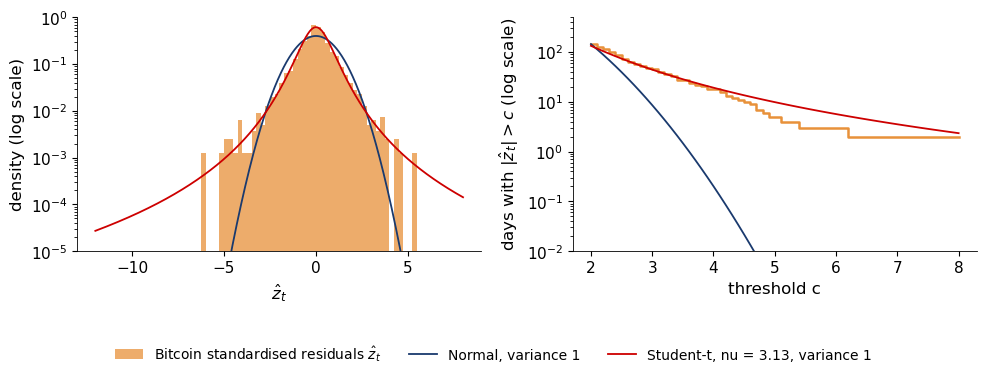

In [7]:
gb_ = fits['Bitcoin']; nu_b_ = gb_.params['nu']; sc_b_ = np.sqrt((nu_b_ - 2) / nu_b_)
zb = gb_.std_resid.dropna(); nz = len(zb)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(zb, bins=np.linspace(-12, 8, 81), density=True, color=BTC, alpha=0.75, label=r'Bitcoin standardised residuals $\hat z_t$')
xx = np.linspace(-12, 8, 801)
ax[0].plot(xx, stats.norm.pdf(xx), color=BLUE, lw=1.3, label='Normal, variance 1')
ax[0].plot(xx, stats.t.pdf(xx / sc_b_, nu_b_) / sc_b_, color=RED, lw=1.3, label=f'Student-t, nu = {nu_b_:.2f}, variance 1')
ax[0].set_yscale('log'); ax[0].set_ylim(1e-5, 1); ax[0].set_xlabel(r'$\hat z_t$'); ax[0].set_ylabel('density (log scale)')
cs = np.linspace(2, 8, 61)
ax[1].plot(cs, [(np.abs(zb) > c_).sum() for c_ in cs], color=BTC, lw=1.8, drawstyle='steps-post')
ax[1].plot(cs, nz * 2 * stats.norm.sf(cs), color=BLUE, lw=1.3)
ax[1].plot(cs, nz * 2 * stats.t.sf(cs / sc_b_, nu_b_), color=RED, lw=1.3)
ax[1].set_yscale('log'); ax[1].set_ylim(0.01, 500); ax[1].set_xlabel('threshold c'); ax[1].set_ylabel(r'days with $|\hat z_t| > c$ (log scale)')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_tails')

**Key numbers** (as on the slide).

In [8]:
print(f'n = {nz}; lowest z = {zb.min():.1f} on {zb.idxmin().date()}')
pd.DataFrame({c_: {'observed': int((np.abs(zb) > c_).sum()), 'expected, Normal': nz * 2 * stats.norm.sf(c_),
                   'expected, Student-t': nz * 2 * stats.t.sf(c_ / sc_b_, nu_b_)} for c_ in [3, 4, 5, 6]}).T.rename_axis('|z| > c')

n = 3183; lowest z = -13.3 on 2020-03-12


,observed,"expected, Normal","expected, Student-t"
|z| > c,,,
3,46.0,8.593451,44.416168
4,18.0,0.201619,19.247481
5,5.0,0.001825,9.875605
6,3.0,0.000006,5.679410
